<a href="https://colab.research.google.com/github/Raymond-Mendez/olist-ecommerce-eda/blob/main/olist_ecommerce_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist Brazilian E-Commerce: Exploratory Data Analysis

An end-to-end exploratory analysis of the **Olist Brazilian E-Commerce dataset** (99,441 real orders, Sep 2016 - Aug 2018) using pandas, SQL and matplotlib. The analysis covers order health, category revenue and satisfaction, customer geography, and the relationship between delivery performance and review scores.


## Dataset

Seven related tables from the Olist e-commerce dataset:

| File | Rows | Description |
|---|---|---|
| `olist_orders_dataset.csv` | 99,441 | Orders with timestamps and status |
| `olist_order_items_dataset.csv` | 112,650 | Items per order with price and freight |
| `olist_customers_dataset.csv` | 99,441 | `customer_id` (per order), `customer_unique_id` (per person), city, state |
| `olist_products_dataset.csv` | 32,951 | Products with category and dimensions |
| `olist_order_reviews_dataset.csv` | 99,224 | Review scores (1–5 stars) |
| `olist_order_payments_dataset.csv` | 103,886 | Payment type and value |
| `product_category_name_translation.csv` | 71 | Portuguese → English category names |


---

## Setup

Libraries are imported and all seven CSVs are read straight from public S3 storage, so the notebook runs end to end with no local downloads. Every table is also loaded into an in-memory SQLite database so parts of the analysis can be written in SQL and the rest in pandas.

In [1]:
# Import libraries
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Confirm versions
print(f"pandas version: {pd.__version__}")
print("Setup complete!")

Matplotlib is building the font cache; this may take a moment.


pandas version: 3.0.5
Setup complete!


In [2]:
# Load the 7 datasets from the curriculum GitHub repo
BASE_URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analytics/eda-project/'

orders = pd.read_csv(BASE_URL + 'olist_orders_dataset.csv')
items = pd.read_csv(BASE_URL + 'olist_order_items_dataset.csv')
customers = pd.read_csv(BASE_URL + 'olist_customers_dataset.csv')
products = pd.read_csv(BASE_URL + 'olist_products_dataset.csv')
reviews = pd.read_csv(BASE_URL + 'olist_order_reviews_dataset.csv')
payments = pd.read_csv(BASE_URL + 'olist_order_payments_dataset.csv')
translation = pd.read_csv(BASE_URL + 'product_category_name_translation.csv')

print(f"orders:      {orders.shape}")
print(f"items:       {items.shape}")
print(f"customers:   {customers.shape}")
print(f"products:    {products.shape}")
print(f"reviews:     {reviews.shape}")
print(f"payments:    {payments.shape}")
print(f"translation: {translation.shape}")

orders:      (99441, 8)
items:       (112650, 7)
customers:   (99441, 5)
products:    (32951, 9)
reviews:     (99224, 7)
payments:    (103886, 5)
translation: (71, 2)


In [3]:
# Set up an in-memory SQLite database with all 7 tables
# This lets you run SQL queries directly against the DataFrames
conn = sqlite3.connect(':memory:')

orders.to_sql('orders', conn, index=False, if_exists='replace')
items.to_sql('items', conn, index=False, if_exists='replace')
customers.to_sql('customers', conn, index=False, if_exists='replace')
products.to_sql('products', conn, index=False, if_exists='replace')
reviews.to_sql('reviews', conn, index=False, if_exists='replace')
payments.to_sql('payments', conn, index=False, if_exists='replace')
translation.to_sql('translation', conn, index=False, if_exists='replace')

print("SQLite database ready. You can now run SQL queries with pd.read_sql().")

SQLite database ready. You can now run SQL queries with pd.read_sql().


---

## 1. Inspecting the orders table

Shape, first rows, and column types for the central `orders` table - 99,441 rows covering order
status and five separate timestamps per order.

In [4]:
# Shape, first rows, and column metadata
print("Shape:", orders.shape)
display(orders.head())

# .info() prints its own output, so it is called directly (not wrapped in print)
orders.info()

Shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


---

## 2. Cleaning the timestamps

All five timestamp columns arrive as strings and three of them contain missing values. Every one is
converted to `datetime`, including `order_estimated_delivery_date`, which is needed later to compare
promised delivery against actual delivery.

In [5]:
# Missing values before cleaning
print("Missing values per column:")
print(orders.isnull().sum())

# All five timestamp columns are converted, not just the two needed for Q8/Q9.
# order_estimated_delivery_date is required later to measure promised vs actual delivery.
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

print("\nDtypes after conversion:")
print(orders.dtypes)

Missing values per column:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Dtypes after conversion:
order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


---

## 3. Order status breakdown (SQL)

How healthy is fulfilment? Order counts and share of total by status, written in SQL against the
in-memory database.

In [6]:
status_summary = pd.read_sql(
    """
    SELECT
        order_status,
        COUNT(*) AS num_orders,
        ROUND(
            COUNT(*) * 100.0 / (SELECT COUNT(*) FROM orders),
            2
        ) AS pct
    FROM orders
    GROUP BY order_status
    ORDER BY num_orders DESC
    """,
    conn
)

print(status_summary)

  order_status  num_orders    pct
0    delivered       96478  97.02
1      shipped        1107   1.11
2     canceled         625   0.63
3  unavailable         609   0.61
4     invoiced         314   0.32
5   processing         301   0.30
6      created           5   0.01
7     approved           2   0.00


---

## 4. Highest-revenue orders (SQL join)

An order can contain several items, so order revenue is `SUM(price + freight_value)` across its
items. This joins `orders` to `items` to surface the ten largest orders.

In [7]:
top_orders = pd.read_sql(
    """
    SELECT
      o.order_id,
      o.order_status,
      ROUND(SUM(i.price + i.freight_value), 2) AS total_revenue
    FROM orders AS o
    JOIN items AS i
      ON o.order_id = i.order_id
    GROUP BY
      o.order_id,
      o.order_status
    ORDER BY
      total_revenue DESC
    LIMIT 10
    """,
    conn
)

print(top_orders)


                           order_id order_status  total_revenue
0  03caa2c082116e1d31e67e9ae3700499    delivered       13664.08
1  736e1922ae60d0d6a89247b851902527    delivered        7274.88
2  0812eb902a67711a1cb742b3cdaa65ae    delivered        6929.31
3  fefacc66af859508bf1a7934eab1e97f    delivered        6922.21
4  f5136e38d1a14a4dbd87dff67da82701    delivered        6726.66
5  2cc9089445046817a7539d90805e6e5a    delivered        6081.54
6  a96610ab360d42a2e5335a3998b4718a    delivered        4950.34
7  b4c4b76c642808cbe472a32b86cddc95     canceled        4809.44
8  199af31afc78c699f0dbf71fb178d4d4    delivered        4764.34
9  8dbc85d1447242f3b127dda390d56e19    delivered        4681.78


---

## 5. Translating product categories

Product categories are stored in Portuguese. Merging the translation table gives English names, and
`value_counts()` shows which categories carry the widest product assortment.

In [8]:
products_eng = products.merge(
    translation,
    on='product_category_name',
    how='left'
)

top_categories = (
    products_eng['product_category_name_english']
      .value_counts()
      .head(10)
)

print(top_categories)



product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64


---

## 6. Revenue and satisfaction by category

Combining items, products and reviews to rank categories by revenue while carrying average review
score alongside it - the two numbers together are what tell you where to invest.

The merge needs care: `reviews` has more rows than unique orders, so joining it naively duplicates
item rows and inflates revenue. It is collapsed to one score per order first, with an assertion to
prove the row count did not change.

In [9]:
# IMPORTANT: reviews contains more rows than unique orders (a few orders were
# reviewed twice). Merging it directly onto items duplicates item rows and
# inflates revenue. Collapse reviews to one score per order first.
print("reviews rows:", len(reviews), "| unique order_id:", reviews['order_id'].nunique())

reviews_by_order = (
    reviews
        .groupby('order_id', as_index=False)['review_score']
        .mean()
)

items_products = items.merge(products_eng, on='product_id', how='left')

items_products_reviews = items_products.merge(
    reviews_by_order,
    on='order_id',
    how='left'
)

# Guard: the merge must not change the number of item rows
print("items rows:", len(items), "| after merges:", len(items_products_reviews))
assert len(items_products_reviews) == len(items), "Merge changed row count - revenue would be inflated"

items_products_reviews['revenue'] = (
    items_products_reviews['price'] + items_products_reviews['freight_value']
)

print("Total revenue (all items): R$", round(items_products_reviews['revenue'].sum(), 2))

category_summary = (
    items_products_reviews
        .groupby('product_category_name_english')
        .agg(
            total_revenue=('revenue', 'sum'),
            avg_review=('review_score', 'mean'),
            n_items=('order_id', 'count')
        )
        .sort_values('total_revenue', ascending=False)
        .head(10)
        .round(2)
)

print()
print(category_summary)

reviews rows: 99224 | unique order_id: 98673
items rows: 112650 | after merges: 112650
Total revenue (all items): R$ 15843553.24

                               total_revenue  avg_review  n_items
product_category_name_english                                    
health_beauty                     1441248.07        4.14     9670
watches_gifts                     1305541.61        4.02     5991
bed_bath_table                    1241681.72        3.90    11115
sports_leisure                    1156656.48        4.11     8641
computers_accessories             1059272.40        3.93     7827
furniture_decor                    902511.79        3.91     8334
housewares                         778397.77        4.05     6964
cool_stuff                         719329.95        4.15     3796
auto                               685384.32        4.06     4235
garden_tools                       584219.21        4.05     4347


---

## 7. Where the customers are (SQL)

The top ten Brazilian states by customer count, using `customer_unique_id` rather than
`customer_id`, since Olist issues a fresh `customer_id` for every order.

customer_id values: 99,441 | customer_unique_id values: 96,096



  customer_state  num_customers
0             SP          40302
1             RJ          12384
2             MG          11259
3             RS           5277
4             PR           4882
5             SC           3534
6             BA           3277
7             DF           2075
8             ES           1964
9             GO           1952


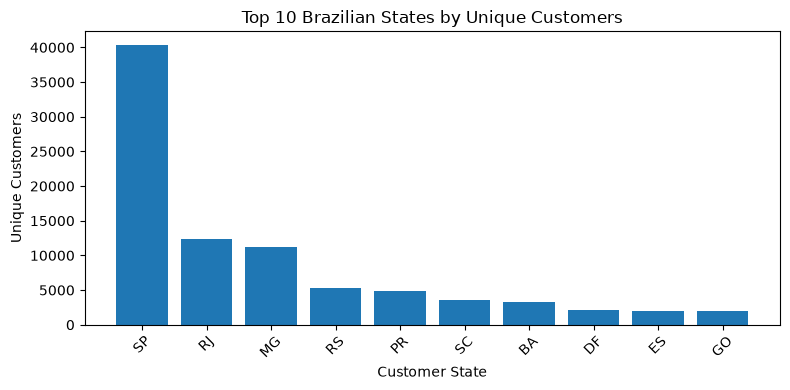

In [10]:
# NOTE: customer_id in Olist is issued per order, so counting it overstates the
# customer base. customer_unique_id is the true person-level identifier.
print("customer_id values:", f"{len(customers):,}",
      "| customer_unique_id values:", f"{customers['customer_unique_id'].nunique():,}")

state_top10 = pd.read_sql(
    """
    SELECT
      customer_state,
      COUNT(DISTINCT customer_unique_id) AS num_customers
    FROM customers
    GROUP BY customer_state
    ORDER BY num_customers DESC
    LIMIT 10
    """,
    conn
)

print()
print(state_top10)

plt.figure(figsize=(8, 4))
plt.bar(state_top10['customer_state'], state_top10['num_customers'])
plt.title('Top 10 Brazilian States by Unique Customers')
plt.xlabel('Customer State')
plt.ylabel('Unique Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---

## 8. Monthly order volume

Order counts per month from `order_purchase_timestamp`. Note that the first and last months of the
dataset are partial periods and are not real swings in demand.

First 3 months:
  year_month  num_orders
0    2016-09           4
1    2016-10         324
2    2016-12           1

Last 3 months:
   year_month  num_orders
22    2018-08        6512
23    2018-09          16
24    2018-10           4


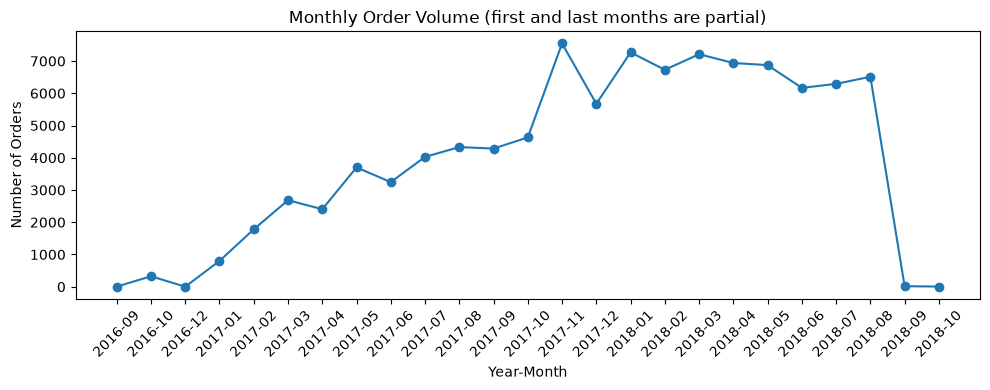

In [11]:
monthly_counts = (
    orders['order_purchase_timestamp']
        .dt.to_period('M')
        .value_counts()
        .sort_index()
)

monthly_orders = monthly_counts.reset_index()
monthly_orders.columns = ['year_month', 'num_orders']
monthly_orders['year_month'] = monthly_orders['year_month'].astype(str)

# The first and last months of this dataset are partial and must not be read
# as growth or collapse.
print("First 3 months:")
print(monthly_orders.head(3))
print("\nLast 3 months:")
print(monthly_orders.tail(3))

plt.figure(figsize=(10, 4))
plt.plot(monthly_orders['year_month'], monthly_orders['num_orders'], marker='o')
plt.title('Monthly Order Volume (first and last months are partial)')
plt.xlabel('Year-Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---

## 9. Does delivery speed affect review scores?

A real business question: do customers who receive orders faster leave better reviews? This measures
delivery time per order, correlates it with review score (Spearman, since the rating is ordinal),
and compares average delivery time at each star level.

Pearson correlation (delivery_days vs review_score):  -0.334
Spearman correlation (delivery_days vs review_score): -0.235

   review_score  delivery_days
0             1          20.88
1             2          16.22
2             3          13.78
3             4          11.84
4             5          10.21


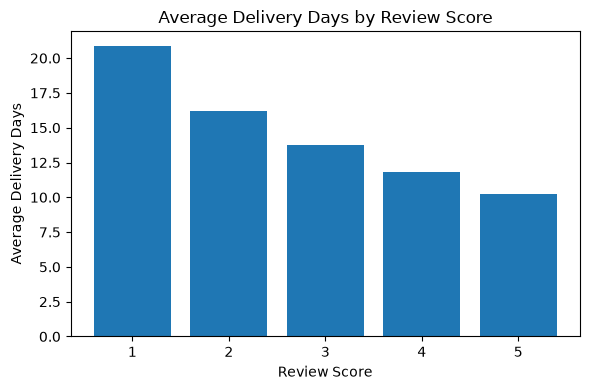

In [12]:
orders_nonnull = orders[orders['order_delivered_customer_date'].notna()].copy()

orders_nonnull['delivery_days'] = (
    orders_nonnull['order_delivered_customer_date']
    - orders_nonnull['order_purchase_timestamp']
).dt.days

orders_reviews = orders_nonnull.merge(
    reviews_by_order,
    on='order_id',
    how='inner'
)

# review_score is an ordinal 1-5 rating, so Spearman is the more defensible
# statistic. Pearson is reported alongside it for comparison.
pearson = orders_reviews['delivery_days'].corr(orders_reviews['review_score'])
spearman = orders_reviews['delivery_days'].corr(orders_reviews['review_score'], method='spearman')

print("Pearson correlation (delivery_days vs review_score): ", round(pearson, 3))
print("Spearman correlation (delivery_days vs review_score):", round(spearman, 3))

avg_delivery_by_score = (
    orders_reviews
        .groupby(orders_reviews['review_score'].round().astype(int), as_index=False)['delivery_days']
        .mean()
        .rename(columns={'review_score': 'review_score'})
        .sort_values('review_score')
        .round(2)
)

print()
print(avg_delivery_by_score)

plt.figure(figsize=(6, 4))
plt.bar(avg_delivery_by_score['review_score'], avg_delivery_by_score['delivery_days'])
plt.title('Average Delivery Days by Review Score')
plt.xlabel('Review Score')
plt.ylabel('Average Delivery Days')
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()

In [13]:
# Follow-up enabled by parsing order_estimated_delivery_date in Q2:
# how often is Olist late, and what does being late cost in stars?
delivered = orders[orders['order_delivered_customer_date'].notna()].copy()
delivered['days_vs_promise'] = (
    delivered['order_delivered_customer_date'] - delivered['order_estimated_delivery_date']
).dt.days
delivered['was_late'] = delivered['days_vs_promise'] > 0

late_reviews = delivered.merge(reviews_by_order, on='order_id', how='inner')

print("Late delivery rate:", f"{late_reviews['was_late'].mean() * 100:.1f}%")
print()
print(
    late_reviews
        .groupby('was_late')
        .agg(orders=('order_id', 'count'), avg_review=('review_score', 'mean'))
        .round(2)
)

Late delivery rate: 6.7%

          orders  avg_review
was_late                    
False      89448        4.29
True        6382        2.27


**Interpretation:** Delivery speed and satisfaction move together. Orders rated 1 star waited
roughly twice as long as orders rated 5 stars, and average delivery time falls monotonically at
every step from 1 star up to 5 stars. The Spearman correlation is negative and moderate, so speed
is clearly *a* driver of the rating but not the only one - plenty of fast deliveries still get low
scores, meaning product and seller quality matter too.

---

## 10. Findings


## Executive Summary

**Business health.** Olist processed 99,441 orders between September 2016 and August 2018, worth
R$15.84M in item revenue. 97.0% of those orders were delivered and only 0.6% were cancelled, so
fulfilment is reliable. Monthly volume grew from roughly 300 orders in late 2016 to a 7,544-order
peak in November 2017 (Black Friday), then settled into a stable band of about 6,200-7,200 orders
per month through mid-2018. The honest read is *strong growth that has plateaued*, not continuing
growth: the first months (4 orders in Sep 2016) and the last months (16 orders in Sep 2018) are
partial data-collection artefacts and must be excluded from any trend claim.

**Where to invest.** Revenue is concentrated in a handful of categories. health_beauty (R$1.44M,
4.14 avg rating), watches_gifts (R$1.31M, 4.02) and sports_leisure (R$1.16M, 4.11) all combine high
revenue with above-average satisfaction, making them the safest places to add inventory and ad
spend. bed_bath_table is the outlier that needs attention: it is the third-largest revenue category
(R$1.24M) and the highest-volume one (11,115 items), but carries the weakest rating of the top
group at 3.90 - a lot of turnover attached to relatively unhappy customers.

**Customers and delivery.** The customer base is 96,096 unique people, and it is heavily
concentrated: Sao Paulo alone accounts for 41.9% of customers and the top three states (SP, RJ, MG)
account for 66.5%. Repeat purchasing is almost non-existent at 3.1%, so this is effectively a
one-purchase marketplace - growth depends on acquisition, and every first order has to land well.
Delivery speed is the clearest lever on that first impression. Average delivery time falls at every
rating step, from 20.9 days for 1-star orders to 10.2 days for 5-star orders (Spearman -0.235).
The sharper signal is the promise, not the speed: only 6.7% of orders arrive after the estimated
delivery date, but those late orders average **2.27 stars against 4.29 for on-time orders** - a
two-star penalty.

**Recommendation.** Treat the estimated delivery date as the metric that matters, not average
transit time. Because late orders are only 6.7% of volume but cost roughly two stars each, fixing
them is a small, targeted operational problem with an outsized effect on ratings. Start with the
long-tail states outside the SP/RJ/MG core, where distance from sellers makes the promise hardest
to keep, and pad the estimate there rather than letting it slip. A companion review of
bed_bath_table sellers would address the largest pool of dissatisfaction inside the revenue base.


---

## Data Quality Notes

Issues found in the raw data that affect how the results above should be read:

1. **`reviews` is not one row per order.** It has 99,224 rows but only 98,673 unique `order_id`
   values. Joining it straight onto `items` duplicates item rows and inflates revenue by about
   R$72K. Q6 collapses reviews to one score per order first, and asserts that the row count is
   unchanged by the merge.
2. **`customer_id` is not a customer.** Olist issues a new `customer_id` per order (99,441 of them)
   while `customer_unique_id` identifies the actual person (96,096). Counting the wrong one
   overstates the customer base by 3.5% and hides the fact that repeat purchasing is only 3.1%.
3. **The time series is truncated at both ends.** September 2016 (4 orders) and September-October
   2018 (16 and 4 orders) are partial periods, not real collapses in demand.
4. **Missing delivery timestamps.** 2,965 orders have no `order_delivered_customer_date` and 1,783
   have no carrier date, mostly cancelled or unavailable orders. Delivery analysis excludes them.
5. **Revenue definition.** Revenue here is `price + freight_value` from `items`. It is not the same
   as the `payments` table total, which includes instalment behaviour and vouchers.
